# 04 · Modelo predictivo de demanda semanal

**Proyecto integrador – Equipo 4** · Responsable: **Samuel**

**Pregunta de negocio:** *¿cuántas unidades de cada producto se venderán la próxima semana?* Con esa cifra el área de compras decide cuánto reponer.

- **Tipo de problema:** aprendizaje **supervisado de regresión**. La variable objetivo es `unidades` (unidades vendidas de un producto en una semana).
- **Alcance:** los **300 productos con demanda más recurrente** (los que se vendieron en más semanas).
- **Modelos comparados:** regresión lineal (Ridge), árbol de decisión, Random Forest y Gradient Boosting, contra dos **líneas base** que cualquier persona usaría sin modelo: *repetir la semana anterior* y *promedio de las últimas 4 semanas*.

**Métricas (explicadas sin jerga):**

| Métrica | Qué significa | Ejemplo |
|---|---|---|
| **RMSE** | Error típico en unidades; castiga más los errores grandes | RMSE = 160 → en promedio el pronóstico se aleja unas 160 unidades, con más peso en los fallos grandes |
| **MAE** | Error promedio en unidades, sin castigo extra | Si un producto vende 100 y se pronosticó 80, el error es 20 |
| **R²** | Qué parte de la variación de la demanda explica el modelo (1 = perfecto, 0 = igual que usar el promedio) | R² = 0,54 → explica el 54 % de las subidas y bajadas |
| **WAPE** | Error total como % de las unidades vendidas | WAPE = 50 % → por cada 100 unidades vendidas, el pronóstico se equivoca en 50 sumando todos los productos |
| **Sesgo** | Si el modelo tiende a pronosticar de más (+) o de menos (−) | −3 % → pronostica un 3 % menos de lo que se vende |

La métrica principal es el **RMSE**, como propone la guía del proyecto.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from src import config, modelado
from src import visualizacion as viz
viz.aplicar_estilo()

ventas = pd.read_parquet(config.VENTAS_LIMPIAS)
festivos = pd.read_csv(config.FESTIVOS_LIMPIOS, parse_dates=["fecha"])

## 1. Panel semanal producto × semana
Una fila por producto y semana (lunes a domingo). Si un producto no se vendió en una semana, esa semana queda con **0 unidades**: también es información para el modelo. Se descartan la primera y la última semana del dataset porque están incompletas.

In [2]:
panel = modelado.construir_panel_semanal(ventas, festivos)
print(f"Filas: {len(panel):,} | productos: {panel['codigo_producto'].nunique()} | "
      f"semanas: {panel['semana_inicio'].nunique()} ({panel['semana_inicio'].min():%d-%m-%Y} a {panel['semana_inicio'].max():%d-%m-%Y})")
print(f"Semanas con 0 unidades: {(panel['unidades'] == 0).mean():.1%}")
cubre = panel["ingreso"].sum() / ventas.loc[ventas.tipo_transaccion == 'Venta', 'importe'].sum()
print(f"Estos 300 productos representan el {cubre:.1%} del ingreso total de la tienda.")
panel.head()

Filas: 31,147 | productos: 300 | semanas: 104 (07-12-2009 a 28-11-2011)
Semanas con 0 unidades: 3.5%
Estos 300 productos representan el 30.3% del ingreso total de la tienda.


,codigo_producto,semana_inicio,unidades,ingreso,clientes,pedidos,precio_medio,demanda_tienda,festivos_semana,descripcion
0,15036,2009-12-07,103.00,79.30,4.00,8.00,0.77,"116,251.00",0,ASSORTED COLOURS SILK FAN
1,15036,2009-12-14,63.00,58.50,3.00,9.00,0.93,"136,253.00",0,ASSORTED COLOURS SILK FAN
2,15036,2009-12-21,103.00,71.50,2.00,5.00,0.69,"27,790.00",1,ASSORTED COLOURS SILK FAN
3,15036,2009-12-28,0.00,0.00,0.00,0.00,0.69,NaN,2,ASSORTED COLOURS SILK FAN
4,15036,2010-01-04,192.00,124.80,4.00,4.00,0.65,"96,054.00",0,ASSORTED COLOURS SILK FAN


## 2. Variables predictoras
Todas se calculan **solo con semanas anteriores** a la que se quiere predecir (con `shift`), para no "hacer trampa" usando información del futuro (*fuga de datos*).

In [3]:
datos = modelado.crear_variables(panel)
descripcion_vars = {
    "lag_1 … lag_4": "Unidades vendidas 1, 2, 3 y 4 semanas atrás",
    "media_4 / media_8 / media_12": "Promedio de unidades de las últimas 4, 8 y 12 semanas",
    "desv_4 / max_4": "Variabilidad y máximo de las últimas 4 semanas",
    "semanas_con_venta_8": "En cuántas de las últimas 8 semanas hubo venta (regularidad)",
    "media_historica": "Promedio de todas las semanas anteriores del producto",
    "semanas_desde_lanzamiento": "Antigüedad del producto en el catálogo",
    "precio_lag_1": "Precio promedio de la semana anterior",
    "clientes_lag_1 / pedidos_lag_1": "Clientes y pedidos distintos de la semana anterior",
    "demanda_tienda_lag_1": "Unidades totales de la tienda la semana anterior (ritmo general)",
    "semana_anio / mes": "Calendario (estacionalidad)",
    "festivos_semana": "Número de festivos en la semana (la tienda no vende en festivos)",
    "estacional_52": "Unidades vendidas en la misma época del año anterior",
    "tiene_historia_anual": "1 si el producto ya tiene un año de historia",
    "indice_estacional": "Cuánto subió o bajó el producto en esa época el año anterior frente a su nivel normal",
}
pd.DataFrame(descripcion_vars.items(), columns=["variable", "significado"])

,variable,significado
0,lag_1 … lag_4,"Unidades vendidas 1, 2, 3 y 4 semanas atrás"
1,media_4 / media_8 / media_12,"Promedio de unidades de las últimas 4, 8 y 12 ..."
2,desv_4 / max_4,Variabilidad y máximo de las últimas 4 semanas
3,semanas_con_venta_8,En cuántas de las últimas 8 semanas hubo venta...
4,media_historica,Promedio de todas las semanas anteriores del p...
5,semanas_desde_lanzamiento,Antigüedad del producto en el catálogo
6,precio_lag_1,Precio promedio de la semana anterior
7,clientes_lag_1 / pedidos_lag_1,Clientes y pedidos distintos de la semana ante...
8,demanda_tienda_lag_1,Unidades totales de la tienda la semana anteri...
9,semana_anio / mes,Calendario (estacionalidad)


## 3. División temporal y validación cruzada
- **Prueba:** las **últimas 12 semanas** (12-sep a 4-dic-2011). El modelo nunca las ve durante el entrenamiento. Coinciden con la temporada alta, el periodo más exigente.
- **Entrenamiento:** todas las semanas anteriores.
- **Ajuste de hiperparámetros:** búsqueda aleatoria con **validación cruzada temporal de 4 pliegues**. Cada pliegue entrena con el pasado y valida con las 8 semanas siguientes. No se usa validación cruzada aleatoria porque mezclaría semanas futuras en el entrenamiento.

Entrenamiento: 25,759 filas · 11-01-2010 a 05-09-2011
Prueba:        3,600 filas · 12-09-2011 a 28-11-2011


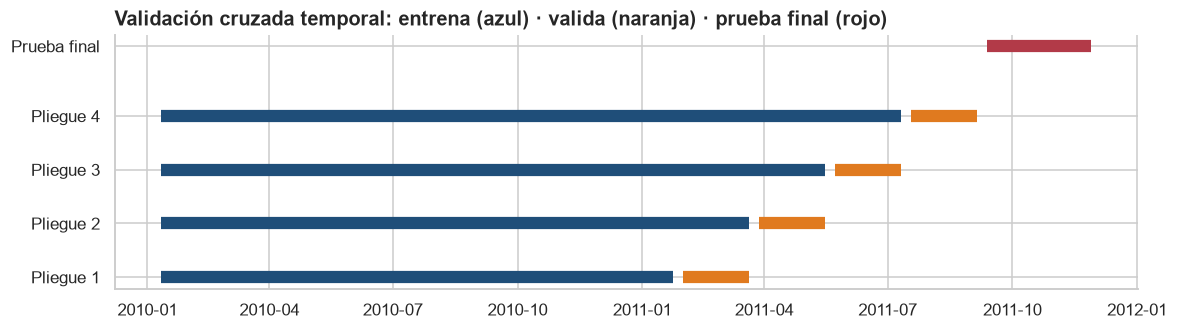

In [4]:
train, test = modelado.dividir_entrenamiento_prueba(datos)
print(f"Entrenamiento: {len(train):,} filas · {train['semana_inicio'].min():%d-%m-%Y} a {train['semana_inicio'].max():%d-%m-%Y}")
print(f"Prueba:        {len(test):,} filas · {test['semana_inicio'].min():%d-%m-%Y} a {test['semana_inicio'].max():%d-%m-%Y}")

semanas_tr = train["semana_inicio"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 3))
for i, (itr, ival) in enumerate(modelado.particiones_temporales(semanas_tr)):
    ax.plot([semanas_tr[itr].min(), semanas_tr[itr].max()], [i, i], lw=8, color=viz.AZUL, solid_capstyle="butt")
    ax.plot([semanas_tr[ival].min(), semanas_tr[ival].max()], [i, i], lw=8, color=viz.NARANJA, solid_capstyle="butt")
ax.plot([test["semana_inicio"].min(), test["semana_inicio"].max()], [4.3, 4.3], lw=8, color=viz.ROJO, solid_capstyle="butt")
ax.set_yticks([0, 1, 2, 3, 4.3], ["Pliegue 1", "Pliegue 2", "Pliegue 3", "Pliegue 4", "Prueba final"])
ax.set_title("Validación cruzada temporal: entrena (azul) · valida (naranja) · prueba final (rojo)")
viz.guardar(fig, "modelo_division_temporal")
plt.show()

## 4. Entrenamiento, ajuste de hiperparámetros y comparación

In [5]:
inicio = time.time()
tabla, modelos, preds = modelado.entrenar_y_comparar(train, test, n_iter=20)
print(f"Tiempo total: {(time.time() - inicio)/60:.1f} min")
tabla.round(3)

Regresión lineal (Ridge)     RMSE CV=  139.78  RMSE prueba=  161.65


Árbol de decisión            RMSE CV=  144.75  RMSE prueba=  170.85


Random Forest                RMSE CV=  138.78  RMSE prueba=  164.85


Gradient Boosting (HistGB)   RMSE CV=  142.01  RMSE prueba=  166.83
Tiempo total: 2.9 min


,modelo,mejores_parametros,RMSE_validacion_cruzada,MAE,RMSE,R2,WAPE_%,Sesgo_%
0,Regresión lineal (Ridge),{'ridge__alpha': 1000},139.78,66.29,161.65,0.54,56.25,1.03
1,Random Forest,"{'n_estimators': 400, 'min_samples_leaf': 20, ...",138.78,65.27,164.85,0.52,55.39,-2.64
2,Gradient Boosting (HistGB),"{'min_samples_leaf': 50, 'max_leaf_nodes': 31,...",142.01,67.35,166.83,0.51,57.15,0.56
3,Base: media 4 semanas,-,NaN,68.98,169.03,0.50,58.53,-6.27
4,Árbol de decisión,"{'min_samples_leaf': 100, 'max_depth': 5}",144.75,66.39,170.85,0.49,56.33,-6.45
5,Base: semana anterior,-,NaN,81.03,202.66,0.28,68.76,-1.00


Mejor modelo (menor RMSE en validación cruzada): Random Forest
Hiperparámetros: {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 12}
Reduce el RMSE 18.7% frente a 'Base: semana anterior'
Reduce el RMSE 2.5% frente a 'Base: media 4 semanas'


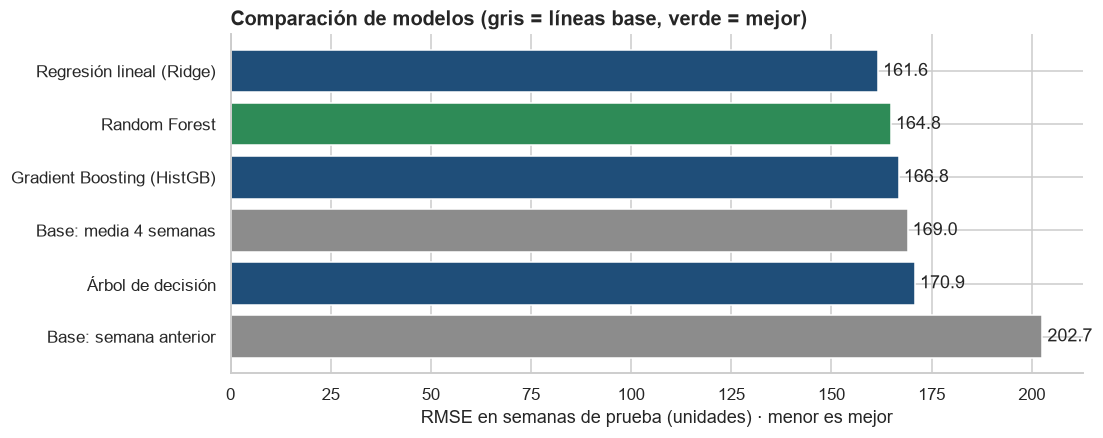

In [6]:
# El modelo se elige por el RMSE de VALIDACIÓN CRUZADA, no por el de prueba:
# así la decisión no se acomoda a las 12 semanas que sirven de examen final.
entrenados = tabla[~tabla["modelo"].str.startswith("Base")]
mejor_nombre = entrenados.sort_values("RMSE_validacion_cruzada")["modelo"].iloc[0]
mejor = modelos[mejor_nombre]
rmse = tabla.set_index("modelo")["RMSE"]
print("Mejor modelo (menor RMSE en validación cruzada):", mejor_nombre)
print("Hiperparámetros:", tabla.set_index("modelo").loc[mejor_nombre, "mejores_parametros"])
for base in ["Base: semana anterior", "Base: media 4 semanas"]:
    print(f"Reduce el RMSE {1 - rmse[mejor_nombre] / rmse[base]:.1%} frente a '{base}'")

fig, ax = plt.subplots(figsize=(10, 4))
colores = [viz.VERDE if m == mejor_nombre else (viz.PALETA[5] if m.startswith("Base") else viz.AZUL) for m in rmse.index]
ax.barh(rmse.index, rmse.values, color=colores)
ax.invert_yaxis()
for i, val in enumerate(rmse.values):
    ax.text(val, i, f" {val:.1f}", va="center")
ax.set_xlabel("RMSE en semanas de prueba (unidades) · menor es mejor")
ax.set_title("Comparación de modelos (gris = líneas base, verde = mejor)")
viz.guardar(fig, "modelo_comparacion_rmse")
plt.show()

**Lectura de la comparación.**
- Los cuatro modelos ajustados quedan muy cerca entre sí. El **Random Forest** tiene el menor error en validación cruzada (RMSE 138,8) y por eso es el **modelo elegido**. En la prueba final obtiene **RMSE 164,9, MAE 65,3 y R² 0,52**.
- La regresión lineal (Ridge) obtuvo un RMSE de prueba un poco menor (161,7), pero **no se eligió por ese resultado**: escoger el modelo mirando la prueba sería ajustar la decisión al examen final. La diferencia entre ambos (2 %) es menor que la variación entre pliegues de la validación cruzada.
- Frente a las líneas base, el modelo elegido **reduce el error 18,7 % respecto de "repetir la semana anterior"** y **2,5 % respecto del promedio de 4 semanas**. La mejora frente al promedio móvil es modesta. Es coherente con lo que mostró el EDA: la demanda de cada producto depende mucho de pedidos mayoristas esporádicos que ninguna variable histórica anticipa.
- El **árbol de decisión individual** es el más débil de los modelos entrenados (RMSE 170,9), por debajo incluso del promedio de 4 semanas. Combinar cientos de árboles (Random Forest) corrige esa inestabilidad.

## 5. Evaluación detallada del mejor modelo

Error a nivel de TOTAL semanal de los 300 productos (WAPE): 12.5%


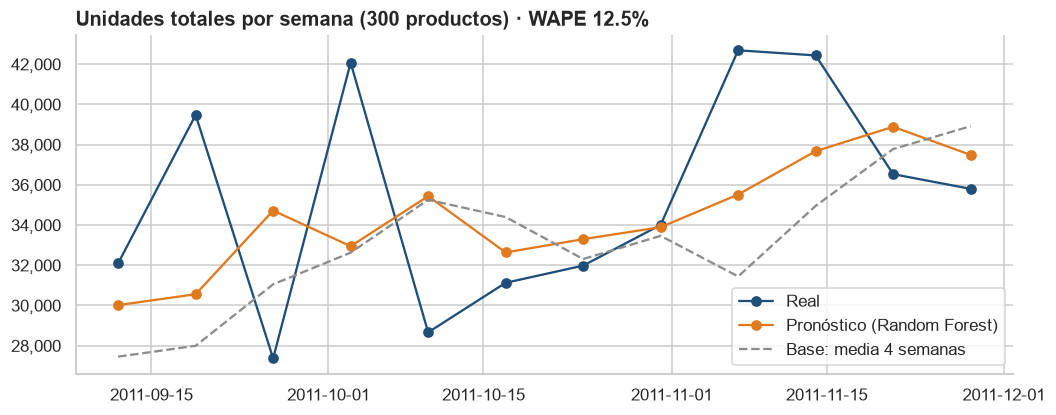

In [7]:
p = preds[["codigo_producto", "descripcion", "semana_inicio", "unidades"]].copy()
p["pronostico"] = preds[mejor_nombre]
p["base_media_4"] = preds["Base: media 4 semanas"]
p["error"] = p["pronostico"] - p["unidades"]

total = p.groupby("semana_inicio")[["unidades", "pronostico", "base_media_4"]].sum()
wape_total = (total["pronostico"] - total["unidades"]).abs().sum() / total["unidades"].sum()
print(f"Error a nivel de TOTAL semanal de los 300 productos (WAPE): {wape_total:.1%}")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(total.index, total["unidades"], marker="o", label="Real", color=viz.AZUL)
ax.plot(total.index, total["pronostico"], marker="o", label=f"Pronóstico ({mejor_nombre})", color=viz.NARANJA)
ax.plot(total.index, total["base_media_4"], ls="--", label="Base: media 4 semanas", color=viz.PALETA[5])
ax.set_title(f"Unidades totales por semana (300 productos) · WAPE {wape_total:.1%}")
ax.legend(); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
viz.guardar(fig, "modelo_real_vs_pronostico_total")
plt.show()

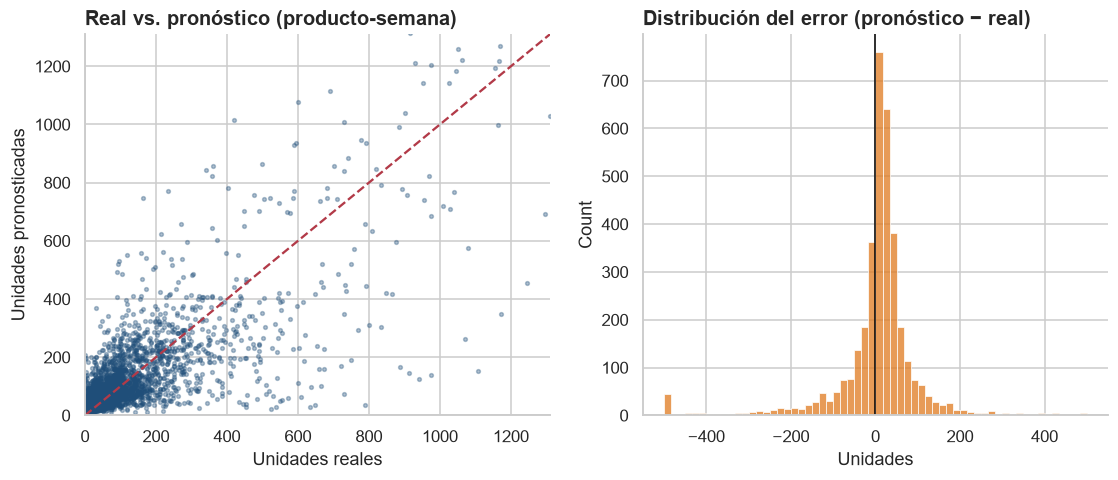

Mediana del error absoluto: 29 unidades
Semanas producto con error de más de 300 unidades: 3.1%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
lim = np.percentile(p["unidades"], 99.5)
axes[0].scatter(p["unidades"], p["pronostico"], s=6, alpha=0.35, color=viz.AZUL)
axes[0].plot([0, lim], [0, lim], color=viz.ROJO, ls="--")
axes[0].set_xlim(0, lim); axes[0].set_ylim(0, lim)
axes[0].set_xlabel("Unidades reales"); axes[0].set_ylabel("Unidades pronosticadas")
axes[0].set_title("Real vs. pronóstico (producto-semana)")
sns.histplot(p["error"].clip(-500, 500), bins=60, ax=axes[1], color=viz.NARANJA)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title("Distribución del error (pronóstico − real)"); axes[1].set_xlabel("Unidades")
viz.guardar(fig, "modelo_dispersion_residuos")
plt.show()
print(f"Mediana del error absoluto: {p['error'].abs().median():.0f} unidades")
print(f"Semanas producto con error de más de 300 unidades: {(p['error'].abs() > 300).mean():.1%}")

In [9]:
# ¿Dónde se equivoca más? Error por nivel de volumen del producto
vol = p.groupby("codigo_producto")["unidades"].mean()
p["nivel_volumen"] = p["codigo_producto"].map(pd.qcut(vol, 4, labels=["Bajo", "Medio-bajo", "Medio-alto", "Alto"]))
por_nivel = p.groupby("nivel_volumen", observed=True).apply(
    lambda g: pd.Series({"productos": g["codigo_producto"].nunique(),
                         "unidades_semana_prom": g["unidades"].mean(),
                         "MAE": g["error"].abs().mean(),
                         "WAPE_%": 100 * g["error"].abs().sum() / g["unidades"].sum()}))
por_nivel.round(1)

,productos,unidades_semana_prom,MAE,WAPE_%
nivel_volumen,,,,
Bajo,75.00,20.00,17.70,88.80
Medio-bajo,75.00,47.30,32.40,68.40
Medio-alto,75.00,93.70,54.70,58.40
Alto,75.00,310.40,156.30,50.40


**Lectura de la evaluación.**
- **Para planear el volumen total** (bodega, transporte, personal) el modelo es muy útil: al sumar los 300 productos, el error semanal es de solo **12,5 %** (WAPE). Los errores de productos individuales se compensan entre sí.
- **Producto por producto** el error relativo es alto. La mitad de las predicciones se equivoca en 29 unidades o menos (mediana), pero hay semanas con desvíos grandes: el 3,1 % falla por más de 300 unidades, casi siempre por un pedido mayorista inesperado.
- El error relativo **baja a medida que sube el volumen del producto**: WAPE de 50 % en los productos de alto volumen frente a 89 % en los de bajo volumen. Para los productos pequeños conviene reponer con reglas simples (stock mínimo) y reservar el modelo para los de mayor rotación.
- La nube de puntos real vs. pronóstico sigue la diagonal; el modelo tiende a quedarse corto en los picos (sesgo de −2,6 %).

## 6. Interpretación: ¿qué variables usa el modelo?
**Importancia por permutación:** se desordena una variable a la vez en los datos de prueba y se mide cuánto empeora el RMSE. Si empeora mucho, el modelo depende de esa variable. Este método sirve igual para cualquier tipo de modelo.

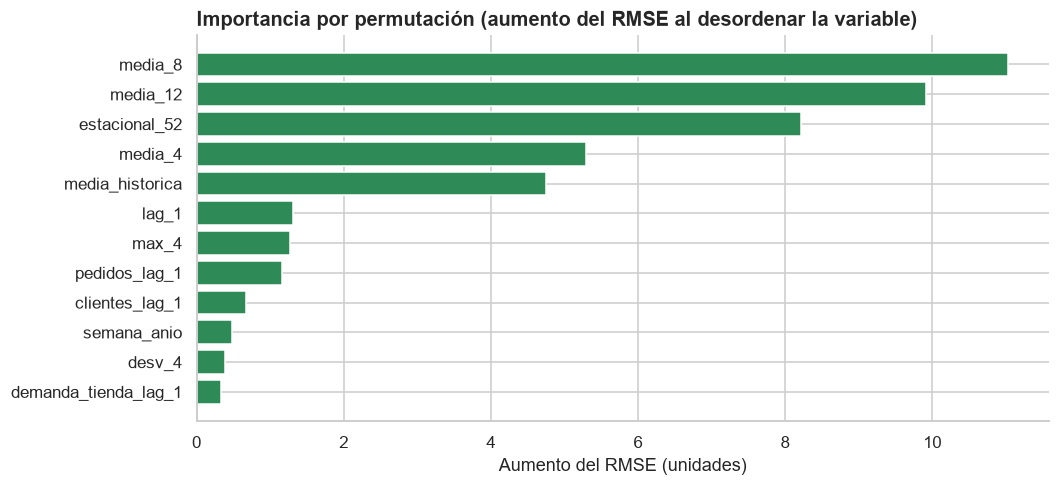

,variable,aumento_RMSE,desv
5,media_8,11.03,0.56
6,media_12,9.91,0.41
19,estacional_52,8.22,0.56
4,media_4,5.29,0.45
10,media_historica,4.75,0.25
0,lag_1,1.31,0.16
8,max_4,1.27,0.10
14,pedidos_lag_1,1.16,0.19
13,clientes_lag_1,0.68,0.13
16,semana_anio,0.48,0.24


In [10]:
imp = permutation_importance(mejor, test[modelado.VARIABLES], test["unidades"], n_repeats=5,
                             random_state=config.SEMILLA, scoring="neg_root_mean_squared_error", n_jobs=-1)
importancia = (pd.DataFrame({"variable": modelado.VARIABLES, "aumento_RMSE": imp.importances_mean,
                             "desv": imp.importances_std})
               .sort_values("aumento_RMSE", ascending=False))
top = importancia.head(12).set_index("variable")["aumento_RMSE"]
viz.barras_horizontales(top, "Importancia por permutación (aumento del RMSE al desordenar la variable)",
                        "Aumento del RMSE (unidades)", color=viz.VERDE)
viz.guardar(plt.gcf(), "modelo_importancia_variables")
plt.show()
importancia.head(12).round(2)

In [11]:
if hasattr(mejor, "named_steps") and "ridge" in mejor.named_steps:
    coef = pd.Series(mejor.named_steps["ridge"].coef_, index=modelado.VARIABLES).sort_values(key=abs, ascending=False)
    display(coef.head(10).round(2).to_frame("coeficiente (variables estandarizadas)"))
else:
    print("El mejor modelo no es lineal; la interpretación se basa en la importancia por permutación.")

El mejor modelo no es lineal; la interpretación se basa en la importancia por permutación.


**Lectura de la interpretación.**
- Las variables más importantes son los **promedios recientes** (8 y 12 semanas) y la **estacionalidad del año anterior** (`estacional_52`). Si se desordena `estacional_52`, el RMSE sube unas 8 unidades. Esto confirma el hallazgo del EDA: la misma época del año pasado es una buena guía, sobre todo en temporada alta.
- El dato de la **semana inmediatamente anterior** (`lag_1`) pesa poco: una sola semana es demasiado ruidosa y el modelo prefiere promedios.
- El **precio**, el **mes** y los **festivos** casi no aportan una vez que se conocen la historia y la estacionalidad del producto. Eso tiene sentido: el precio de cada producto casi no cambió en el periodo.
- *Para el negocio:* el pronóstico se apoya en el ritmo reciente del producto, corregido por lo que pasó en la misma época del año anterior.

## 7. Ejemplos: tres productos de alto volumen en las semanas de prueba

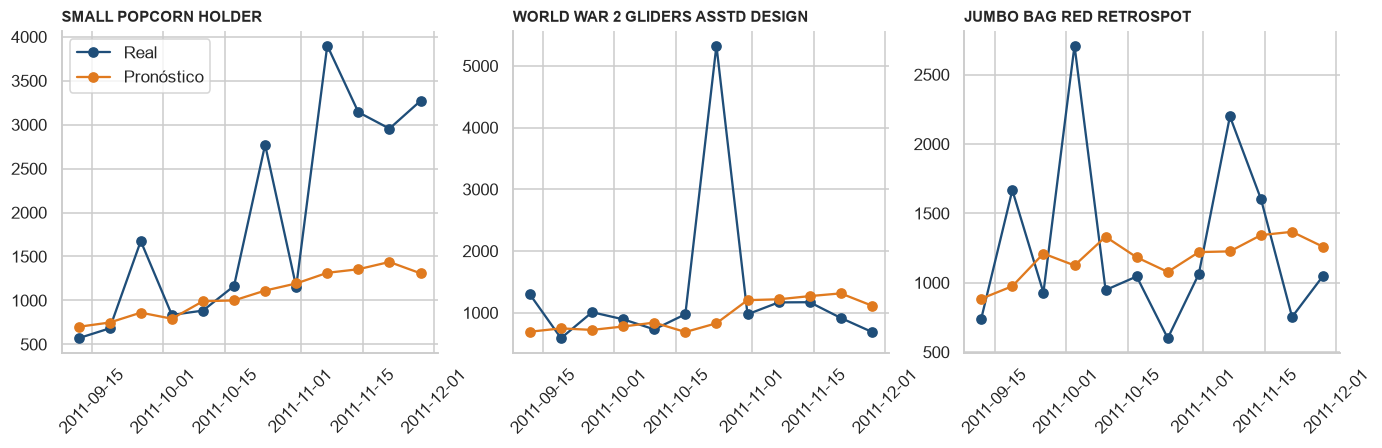

In [12]:
ejemplos = p.groupby("codigo_producto")["unidades"].sum().nlargest(3).index
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, cod in zip(axes, ejemplos):
    g = p[p["codigo_producto"] == cod]
    ax.plot(g["semana_inicio"], g["unidades"], marker="o", label="Real", color=viz.AZUL)
    ax.plot(g["semana_inicio"], g["pronostico"], marker="o", label="Pronóstico", color=viz.NARANJA)
    ax.set_title(g["descripcion"].iloc[0][:32], fontsize=10)
    ax.tick_params(axis="x", rotation=45)
axes[0].legend()
viz.guardar(fig, "modelo_ejemplos_productos")
plt.show()

## 8. Pronóstico para la próxima semana
El mejor modelo se **reentrena con toda la historia** (incluidas las 12 semanas de prueba) y pronostica la semana del **5 al 11 de diciembre de 2011** para los 300 productos. El rango mínimo y máximo usa el error promedio que tuvo cada producto en la prueba, para que compras sepa entre qué valores esperar la demanda.

In [13]:
mae_producto = p.groupby("codigo_producto")["error"].apply(lambda e: e.abs().mean())
proxima = modelado.pronosticar_proxima_semana(mejor, panel, festivos, mae_producto)
print(f"Semana pronosticada: {proxima['semana_inicio'].iloc[0]:%d-%m-%Y}")
print(f"Unidades totales pronosticadas: {proxima['unidades_pronosticadas'].sum():,.0f}")
proxima.head(15)

Semana pronosticada: 05-12-2011
Unidades totales pronosticadas: 34,963


,codigo_producto,descripcion,semana_inicio,unidades_pronosticadas,rango_minimo,rango_maximo,promedio_ultimas_4_semanas
0,22197,SMALL POPCORN HOLDER,2011-12-05,"1,375.00",469.00,"2,281.00","3,317.00"
1,85099B,JUMBO BAG RED RETROSPOT,2011-12-05,"1,374.00",881.00,"1,867.00","1,401.00"
2,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2011-12-05,"1,273.00",668.00,"1,878.00",985.20
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-12-05,"1,183.00",840.00,"1,526.00",888.20
4,84879,ASSORTED COLOUR BIRD ORNAMENT,2011-12-05,"1,164.00",906.00,"1,422.00","1,257.20"
5,21212,PACK OF 72 RETROSPOT CAKE CASES,2011-12-05,712.00,400.00,"1,024.00",459.20
6,84946,ANTIQUE SILVER TEA GLASS ETCHED,2011-12-05,660.00,464.00,856.00,738.50
7,21790,VINTAGE SNAP CARDS,2011-12-05,474.00,323.00,625.00,662.00
8,22178,VICTORIAN GLASS HANGING T-LIGHT,2011-12-05,432.00,89.00,775.00,464.50
9,22355,CHARLOTTE BAG SUKI DESIGN,2011-12-05,420.00,305.00,535.00,573.20


## 9. Exportar resultados (para Power BI y el informe)

In [14]:
config.PROCESSED.mkdir(parents=True, exist_ok=True)
config.REPORTS.mkdir(parents=True, exist_ok=True)
p[["codigo_producto", "descripcion", "semana_inicio", "unidades", "pronostico", "base_media_4", "error"]].round(2) \
    .to_csv(config.PREDICCIONES, index=False, date_format="%Y-%m-%d")
proxima.to_csv(config.PRONOSTICO_PROXIMA_SEMANA, index=False, date_format="%Y-%m-%d")
tabla.round(4).to_csv(config.METRICAS_MODELOS, index=False)
for r in [config.PREDICCIONES, config.PRONOSTICO_PROXIMA_SEMANA, config.METRICAS_MODELOS]:
    print(r.relative_to(config.RAIZ))

data\processed\predicciones_demanda.csv
data\processed\pronostico_proxima_semana.csv
reports\metricas_modelos.csv


## 10. Conclusiones del modelo

1. Se construyó un modelo supervisado de regresión para la **demanda semanal de los 300 productos más recurrentes** (30 % del ingreso de la tienda). Se compararon 4 algoritmos con ajuste de hiperparámetros y **validación cruzada temporal**.
2. El modelo elegido, **Random Forest**, obtiene en las 12 semanas de prueba (temporada alta 2011) **RMSE 164,9, MAE 65,3, R² 0,52 y WAPE 55 %** por producto-semana, y **WAPE 12,5 % en el total semanal**.
3. Supera a las dos líneas base (−18,7 % y −2,5 % de RMSE). La ganancia frente al promedio de 4 semanas es pequeña por la naturaleza mayorista e irregular de la demanda; **se reporta tal cual, sin maquillar**.
4. **Uso recomendado:** planear el volumen total semanal y la reposición de los productos de mayor rotación con el **rango mínimo-máximo** que entrega el modelo, no solo con el número puntual.
5. **Limitaciones:** solo dos años de historia (un único ciclo anual completo para aprender la estacionalidad), pedidos mayoristas imposibles de anticipar con datos históricos y precios casi constantes.
6. **Mejoras posibles:** agregar la cartera de pedidos confirmados de grandes clientes, modelar por separado la demanda minorista y la mayorista, y reentrenar cada semana con los datos nuevos.

Las predicciones de prueba, el pronóstico de la próxima semana y las métricas se exportan para el dashboard de Power BI (página *Pronóstico de demanda*).